# P4 Theory · Transformer와 LLM의 기본 이해 (확장판)

**수업 목표:** 원래 Transformer의 **Encoder–Decoder 아키텍처**를 이해한 후, 사전훈련된 모델을 이용한 **영어→스페인어 번역**과 **Decoder-only 언어 생성**을 연결한다. 마지막으로 두 구조를 결합하는 문서 검색·답변 생성 프로젝트의 기본 아이디어를 이해한다.

**범위:** 총 3주(9시간) 안에 학습하는 기초 내용. 수학적 유도, 역전파, 직접 모델 훈련, 강화학습은 다루지 않는다.

> 핵심 질문: **입력된 문장은 어떻게 숫자가 되고, Transformer는 이를 어떻게 처리하며, 모델은 어떻게 문장을 출력할까?**

**참고:** 기존 `dl_for_text.ipynb`의 텍스트 벡터화·임베딩·Self-Attention·Encoder–Decoder 번역 설명을 기초로 재구성하였다. Original Transformer: Vaswani et al. (2017), *Attention Is All You Need*. Stanford CME295 Lecture 1–3은 주제 구성 참고 자료이다.


## 전체 학습 흐름

| 주차 | 핵심 질문 | 실습 연결 |
|---|---|---|
| 1주차 | 텍스트를 어떻게 숫자로 바꾸고, 토큰 사이의 관계를 어떻게 파악할까? | 토큰·ID·임베딩 모양 확인, 간단한 Attention |
| 2주차 | 원래 Transformer의 Encoder와 Decoder는 어떻게 작동할까? | **영어→스페인어** 사전훈련 번역 모델 |
| 3주차 | Encoder 없이 Decoder만 사용하면 어떻게 문장을 만들까? | 다음 토큰 확률, 텍스트 이어쓰기와 짧은 질의응답 |

각 주차에서 이론을 먼저 학습하고 같은 주제의 실습을 수행한다. **P4 Project**에서는 아래에서 소개하는 Encoder-only의 문서 검색과 Decoder-only의 답변 생성을 연결한다. 프로젝트는 사전훈련 모델을 사용하며 모델을 직접 훈련하지 않는다.


---
# 1. 텍스트는 어떻게 숫자가 되는가? — 토큰화와 임베딩

Transformer는 문자를 직접 계산하지 않는다. **텍스트를 작은 단위로 나누고(토큰화), 정수 ID로 바꾸고, 각 ID를 실수 벡터로 변환**하여 입력한다. 기존 `dl_for_text`의 *텍스트 벡터화 → 단어 임베딩* 설명을 바탕으로, 이후 Attention으로 이어지는 부분만 다시 정리한다.

이 절에서 답할 질문은 세 가지다. (1) 단어와 토큰은 같은가? (2) 정수 ID를 그대로 사용하지 않고 왜 벡터로 바꾸는가? (3) 길이 256인 벡터가 실제로 어떤 모양인가?


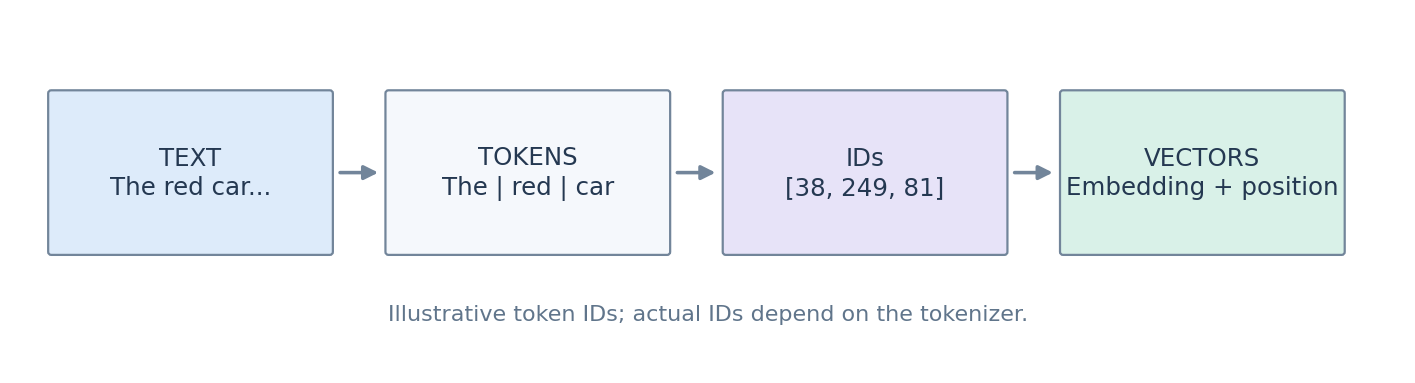

- **토큰화(Tokenization):** 문장을 토큰 단위로 나눈다. 토큰은 단어 전체일 수도, 단어의 일부일 수도 있다.
- **토큰 ID:** 토큰마다 어휘집에서 정한 정수 번호를 부여한다.
- **임베딩(Embedding):** 각 정수 ID를 여러 개의 실수로 구성된 벡터로 바꾼다. ID 숫자 자체가 단어의 의미를 표현하는 것은 아니다.
- **위치 정보(Positional Information):** 토큰의 순서를 반영한다. Attention 계산만으로는 입력 순서를 충분히 구분할 수 없기 때문이다.

> 그림의 ID 숫자는 설명을 위해 만든 예시다. 실제 토큰 분할과 숫자는 사용한 모델에 따라 달라진다.


## 1-1. 텍스트 표준화와 토큰화

예를 들어 **`The red car is fast.`**라는 문장을 처리한다고 하자.

1. **표준화(Standardization):** 필요에 따라 대소문자·공백·기호를 정리한다. 예: `The red car is fast.` → `the red car is fast`. 다만 현대 사전훈련 LLM의 토크나이저는 대소문자나 기호도 정보로 사용하는 경우가 있으므로 **언제나 소문자화·구두점 삭제를 하는 것은 아니다.**
2. **토큰화(Tokenization):** 텍스트를 모델이 사용할 단위로 분리한다. 단어 기준이라면 `the / red / car / is / fast`의 5개가 될 수 있다.
3. **Subword 토큰화:** 실제 사전훈련 모델은 단어를 통째로 처리하기도 하지만 일부 조각으로 나누기도 한다. 예: `unbelievable` → `un / believ / able` *(원리를 위한 가상 분할)*.

**토큰은 반드시 단어 하나가 아니다.** 공백, 문장부호, 단어 일부, 특수 기호가 토큰에 포함될 수 있고, 정확한 결과는 토크나이저마다 다르다.

| 구분 | 예시 | 의미 |
|---|---|---|
| 원문 | `The red car is fast.` | 사람이 읽는 텍스트 |
| 단순한 단어 토큰화 | `the`, `red`, `car`, `is`, `fast` | 설명용 5개 토큰 |
| 실제 모델 토큰화 | 모델마다 다름 | P4 Lab에서 직접 확인 |

번역이나 문장 생성에서는 `[BOS]`, `[EOS]`, `[PAD]`처럼 시작·종료·패딩을 나타내는 **특수 토큰**이 쓰이기도 한다. 그 이름과 사용 여부는 모델마다 다르다.


## 1-2. 어휘집(Vocabulary)과 토큰 ID

모델은 사용할 수 있는 토큰들의 목록인 **어휘집**을 갖고 있다. 각 토큰에는 하나의 **정수 ID**가 부여된다. 예를 들어 *수업용 어휘집*을 다음처럼 만들 수 있다.

| 토큰 | `the` | `red` | `car` | `is` | `fast` |
|---|---:|---:|---:|---:|---:|
| 토큰 ID(가상) | 2 | 3 | 4 | 5 | 6 |

따라서 한 문장은 `[2, 3, 4, 5, 6]`과 같은 정수 배열이 된다.

**중요:** `car=4`, `red=3`이라는 숫자는 사전에서 부여한 **주소**에 가깝다. 4가 3보다 크다고 해서 자동차의 의미가 더 크거나, 두 토큰이 의미적으로 가깝다는 뜻은 아니다.

문장마다 토큰 수가 다를 수 있으므로 여러 문장을 묶어 처리할 때는 **패딩(Padding)**으로 길이를 맞추거나 **Attention Mask**로 패딩을 무시하도록 할 수 있다.


## 1-3. 임베딩(Embedding): ID를 256개의 숫자로 바꾼다

토큰 ID는 단순한 번호이므로, 신경망이 계산하기 좋은 **실수 벡터**로 변환한다. 이를 토큰 임베딩이라고 한다.

예를 들어 어휘집 크기가 10,000이고 임베딩 차원이 **256**이라면 **임베딩 테이블**의 크기는 `(10,000, 256)`이다. 토큰 ID가 4라면 그 테이블에서 4번 행의 256개 숫자를 가져온다. 원래 `dl_for_text`에도 `embed_dim = 256` 예제가 있다.

```text
토큰     ID     256차원 임베딩(앞의 일부만 표시)
the       2     [ 0.12, -0.04,  0.28, ... , -0.03]
red       3     [-0.17,  0.11,  0.06, ... ,  0.09]
car       4     [ 0.05,  0.23, -0.13, ... ,  0.14]
is        5     [ 0.10,  0.02,  0.07, ... , -0.08]
fast      6     [-0.06,  0.19,  0.04, ... ,  0.21]
```

이 수치는 **설명용 가상 값**이다. 실제 모델의 임베딩 값은 사전훈련된 가중치로 결정된다. **256차원은 256개의 단어를 뜻하지 않고, 토큰 하나를 실수 256개로 표현한다는 뜻**이다.

다섯 개 토큰이 모이면 **`(토큰 수 5, 임베딩 차원 256)` = `(5, 256)`** 형태의 행렬이 된다. 배치에 문장 3개가 있으면 예를 들어 `(3, 5, 256)`처럼 표시한다(문장 길이를 5로 맞춘 경우).


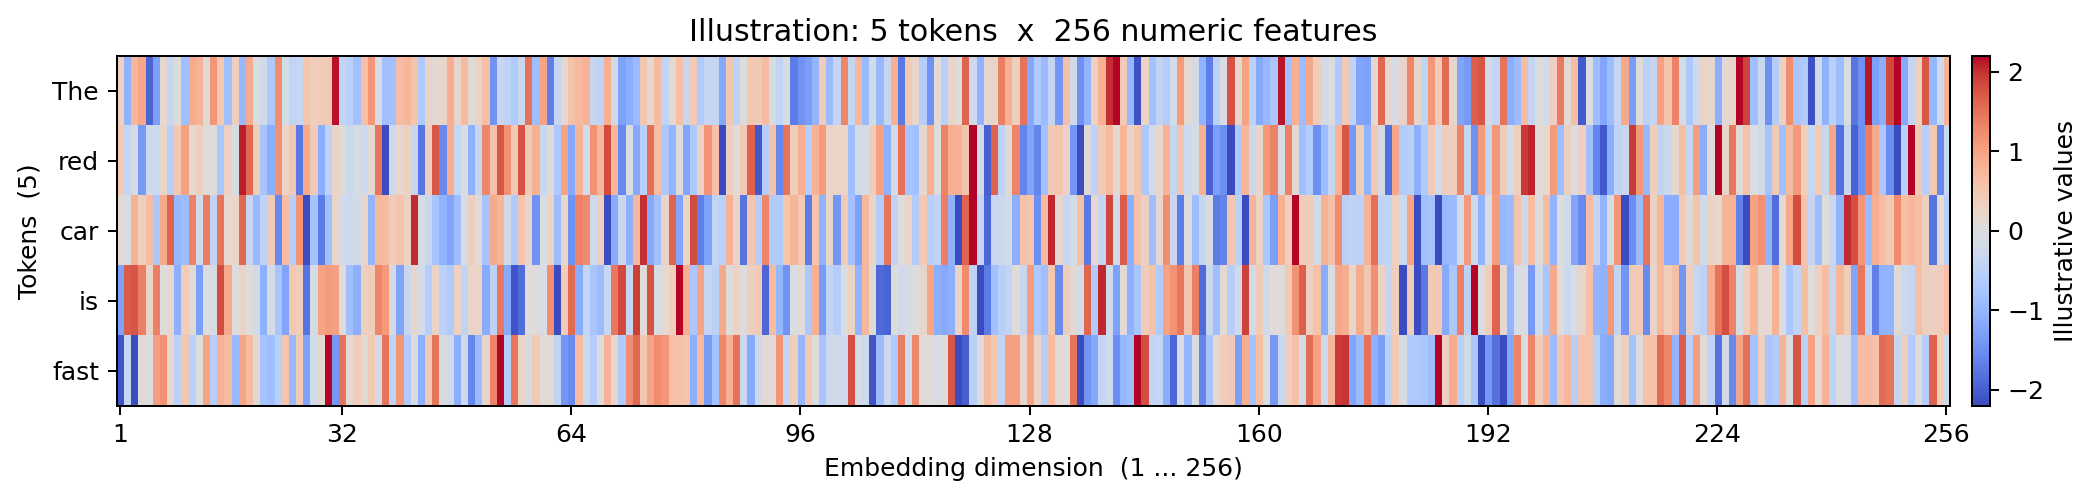

*그림: 256개 차원을 각각 작은 열로 표시한 예시이다. 색은 설명을 위해 만든 숫자값을 뜻하며, 이 그림 자체가 학습된 단어의 의미를 나타내는 것은 아니다.*


### 임베딩 벡터에서 꼭 기억할 점

- 처음 **임베딩 테이블을 무작위로 초기화한 상태**에서는 벡터에 유용한 의미가 담겨 있다고 볼 수 없다. 모델이 사전훈련되는 과정에서 값이 조정되며 언어에 유용한 표현이 형성된다. 이번 P4에서는 직접 훈련하지 않고 **이미 학습된 테이블을 조회**할 수 있다.
- 각 숫자에 `성별`, `색깔` 같은 사람이 정한 뜻이 하나씩 대응하는 것은 아니다. **여러 차원의 패턴 전체**가 유용한 정보를 나타낸다.
- 같은 토큰 ID는 같은 임베딩 테이블의 행을 조회한다. 그러나 이후 **위치 정보와 Attention을 통과한 표현**은 문장·위치에 따라 달라질 수 있다.
- 임베딩 차원은 **모델 설계에 따라 다르다.** 수업의 예시는 256차원으로 통일하되, 사전훈련된 번역 모델은 자신이 정한 다른 차원을 가질 수 있다.


## 1-4. 위치 정보가 필요한 이유

다음 두 문장은 단어 목록이 비슷해도 의미가 다르다.

- `The dog chased the boy.`
- `The boy chased the dog.`

토큰의 **순서**가 바뀌면 누가 쫓는지도 달라진다. 원래 Transformer에서는 각 위치마다 **위치 인코딩(Positional Encoding)**을 만든 뒤 토큰 임베딩에 더했다. 이후 모델에서는 학습된 위치 벡터나 RoPE 등 다른 방식도 사용한다.

```text
[토큰 ID] → [토큰 임베딩: 256차원] ─┐
                                    ├→ [위치가 반영된 표현: 256차원] → Attention
[토큰 위치] → [위치 정보: 256차원] ───┘
```

이때 **`(5, 256)`의 모양 자체는 바뀌지 않지만**, 각 토큰의 벡터에 순서 정보가 반영된다.

> **P4 Lab 연결:** 먼저 다운로드 없이 직접 만든 `(5, 256)` 행렬을 보고, 그다음 실제 번역 모델의 토크나이저와 **사전훈련된 임베딩 벡터**를 확인한다. 두 벡터를 혼동하지 않는 것이 중요하다.


### 1절 핵심 정리

**텍스트 → 토큰 → 토큰 ID → 토큰 임베딩 + 위치 정보 → Transformer 입력 표현**

**확인 질문:** `car`의 ID가 4이고 `red`의 ID가 3이라면, ID 차이가 작은 두 토큰의 의미도 비슷하다고 말할 수 있을까? 256차원 임베딩으로 표현된 5개 토큰의 행렬 크기는 무엇인가?


---
# 2. 단어 사이의 관계를 어떻게 파악하는가? — Self-Attention과 Q·K·V

1절까지는 각 토큰을 **256차원 벡터**로 표현했다. 하지만 단어의 의미는 주변 단어에 따라 달라진다. 예를 들어 `bank`는 `river`와 함께 쓰일 때와 `money`와 함께 쓰일 때 다르게 해석된다.

**Self-Attention**은 각 토큰의 표현을 만들 때 같은 시퀀스의 **어떤 다른 토큰을 어느 정도 참고할지** 계산한다. 즉, 개별 토큰 임베딩을 **문맥이 반영된 표현**으로 바꾸는 핵심 단계다.


## 2-1. 왜 다른 토큰을 참고해야 할까?

문장 **`The dog chased the ball.`**을 생각해 보자.

- `dog`: 쫓는 주체
- `chased`: 주체와 대상의 관계를 나타내는 동사
- `ball`: 쫓는 대상

`chased`를 표현할 때 `dog`와 `ball`의 정보를 참고하면 문장 속 행동을 더 잘 표현할 수 있다. Self-Attention은 이러한 관계를 **고정된 문법 규칙을 직접 입력하지 않고, 학습된 벡터 연산으로** 반영한다.

단, 실제 모델의 Attention 점수가 언제나 문법적 관계를 정확히 설명하는 것은 아니다. 아래 가중치는 **원리를 설명하기 위한 교육용 값**이다.

Self-Attention의 동작을 3단계로 생각할 수 있다.

1. 현재 토큰이 다른 토큰들과 **얼마나 관련되어 있는지** 점수를 계산한다.
2. 점수를 **합이 1인 가중치**로 변환한다(Softmax).
3. 다른 토큰이 제공하는 정보 벡터를 **가중합**하여 현재 토큰의 새로운 표현을 계산한다.


## 2-2. Query·Key·Value (Q·K·V)는 각각 무엇인가?

도서관에서 필요한 책을 찾는 과정을 생각해 보자.

| 역할 | 뜻 | 비유 |
|---|---|---|
| **Query (Q)** | 지금 어떤 정보를 찾고 싶은가? | 검색자가 입력한 검색어 |
| **Key (K)** | 해당 정보가 무엇과 관련 있는가? | 책을 찾기 위한 검색 표지 |
| **Value (V)** | 실제로 어떤 정보를 전달하는가? | 책의 내용 |

`chased` 토큰이 **Query**를 만들고, 각 토큰이 가진 **Key**와의 관련성을 비교한다. 관련성이 높은 토큰들의 **Value**가 현재 토큰의 새 표현에 더 큰 비중으로 반영된다.

중요한 구분은 다음과 같다.

- Q·K·V는 **서로 다른 단어의 종류**가 아니다.
- 실제 Transformer에서는 각 토큰 표현에 서로 다른 **학습된 선형 변환**을 적용하여 Q·K·V를 만든다.
- **Self-Attention**에서는 Q·K·V의 출발점이 **같은 시퀀스의 토큰 표현들**이다. 다만 실제 세 벡터의 값은 서로 다를 수 있다.


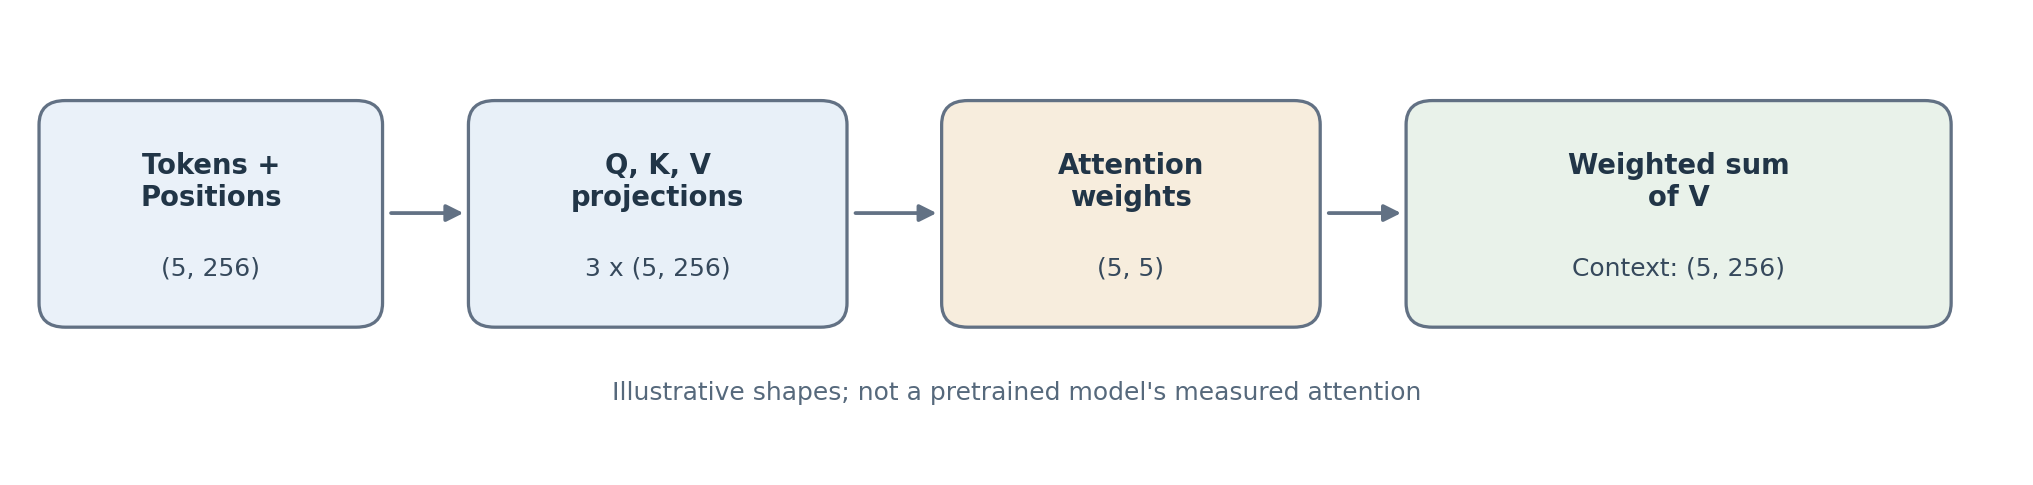

*그림: 토큰이 5개이고 벡터 차원이 256인 교육용 예시. 학습된 Q·K·V의 실제 값이 아니라 **계산 단계와 텐서 형태**를 나타낸다.*


## 2-3. 가중치가 실제로 어떻게 쓰이는가?

현재 토큰이 `chased`라고 하자. 설명을 위해 다른 다섯 토큰에 대한 Attention 가중치를 다음처럼 정해 보자.

| 참고하는 토큰 | the (첫째) | dog | chased | the (넷째) | ball |
|---|---:|---:|---:|---:|---:|
| 가중치(가상) | 0.05 | **0.40** | 0.10 | 0.05 | **0.40** |

가중치의 합은 `1.00`이다. `dog`와 `ball`이 각각 40%의 비중으로 반영되는 상황이다. 다음 단계에서는 이 가중치를 각 토큰의 **V 벡터에 곱해 합친다**.

```text
새로운 'chased' 표현 =
    0.05 × V(the₁) + 0.40 × V(dog) + 0.10 × V(chased)
  + 0.05 × V(the₂) + 0.40 × V(ball)
```

각 V가 **256차원**이므로 결과도 **256개의 숫자**로 된 벡터다. **학생이 256개의 곱셈을 직접 계산할 필요는 없다.** `어느 토큰을 더 참고했는가`와 `출력 모양이 그대로 유지되는가`를 보면 된다.

위 값은 흐름을 이해하기 위한 가상 사례이며, 바로 아래 그림의 가중치는 별도의 **교육용 Q·K 예제**에서 계산한 값이다.


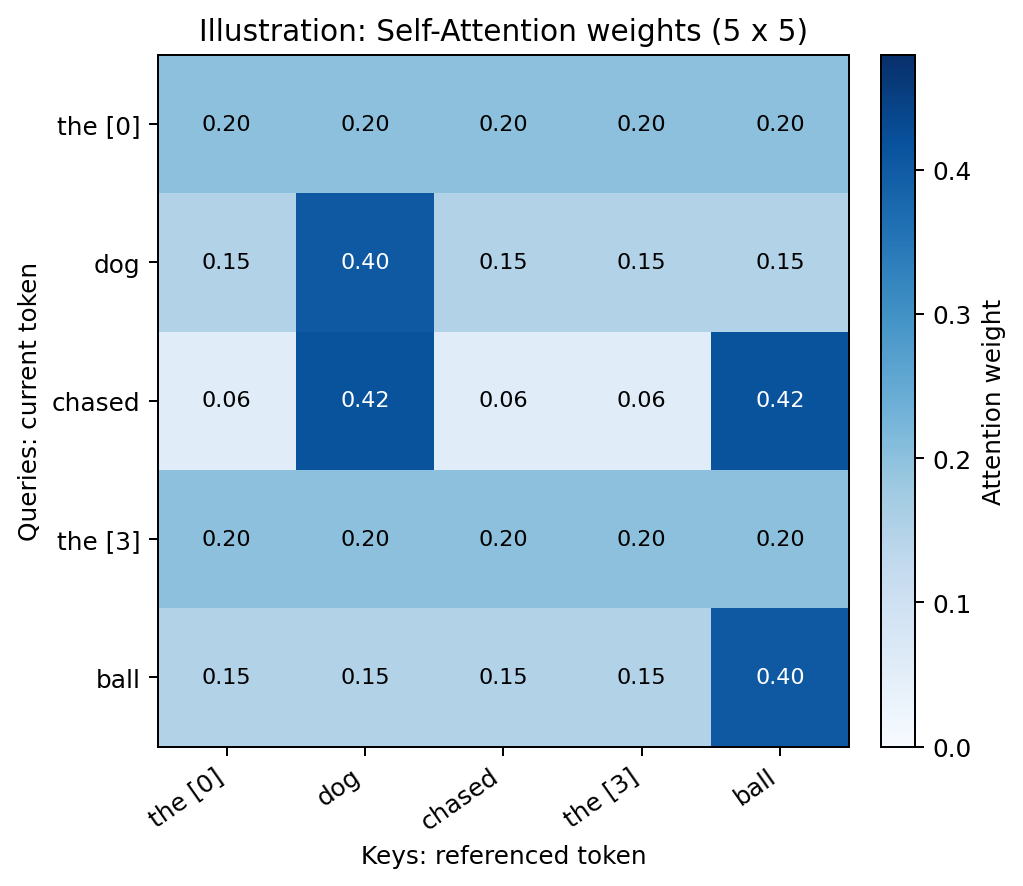

*가로축은 참고되는 토큰(Key), 세로축은 현재 토큰(Query)이다. `chased` 행에서 `dog`와 `ball`에 비교적 큰 가중치가 부여되도록 설계한 **설명용 모델**이다. 실제 사전훈련 모델의 해석 결과가 아니다.*


## 2-4. 256차원이어도 핵심은 단순하다

토큰 5개, 임베딩 차원 256인 **한 개의 Attention Head를 단순화한 예**를 생각해 보자.

| 단계 | 입력·출력 모양 | 의미 |
|---|---|---|
| 토큰 표현 X | `(5, 256)` | 다섯 토큰의 벡터 |
| Q·K·V | 각 `(5, 256)` | 정보를 찾고·비교하고·전달하기 위한 표현 |
| 토큰 사이의 관련성 | `(5, 5)` | 토큰 5개 각각이 다른 5개를 참고하는 정도 |
| V의 가중합 결과 | `(5, 256)` | **문맥이 반영된 다섯 개의 새 벡터** |

따라서 Attention이 하는 일은 **256차원을 5차원으로 줄이는 것**이 아니다. 다섯 토큰이 서로를 참고하도록 하는 **5×5 가중치 표**를 만든 뒤, 그 표를 이용해 **256차원 표현을 갱신**하는 것이다.

필요하면 식 하나만 기억하면 된다.

$$
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}\right)V
$$

이 수식은 **Q와 K로 가중치를 만든 다음 V의 가중합을 구한다**는 설명을 압축한 것이다. 여기서는 수식 전개·미분이나 256차원 숫자 계산을 하지 않는다.


## 2-5. Multi-Head Attention은 무엇을 더하는가?

하나의 Head는 하나의 방식으로 관련성을 계산한다. **Multi-Head Attention**은 여러 Head가 각각 다른 Q·K·V 변환을 사용해 관계를 살펴보고, 그 결과를 합친다.

예를 들어 모델의 표현 차원 `d_model=256`이고 **Head가 4개이며 각 Head의 차원이 64**가 되도록 설계할 수 있다. 이때 각 Head가 서로 다른 관계를 포착하도록 학습될 수 있다.

```text
토큰 표현: (5, 256)
       ├─ Head 1: 관심 관계 A  ─┐
       ├─ Head 2: 관심 관계 B  ─┤
       ├─ Head 3: 관심 관계 C  ─┤→ 결합·출력 변환 → (5, 256)
       └─ Head 4: 관심 관계 D  ─┘
```

주의: 각 Head의 출력이 꼭 64차원인 것은 **아키텍처에 따라 달라진다**. 여기서는 계산 구조를 이해하기 위한 한 가지 설정이다. 실제 Head가 인간이 이름 붙인 관계만 담당한다고 단정할 수도 없다.

원래 Transformer 블록은 이 Multi-Head Attention에 **Feed Forward 층, 잔차 연결(Add), 정규화(Norm)** 등을 결합한다. 이번 P4에서는 이들이 안정적인 정보 처리에 도움을 준다는 수준에서만 이해한다.


## 2-6. 모든 Attention이 같은 범위를 볼까?

원래 Transformer를 이해하기 위해 **세 가지 Attention**을 구분해 두자.

| 종류 | Q의 출처 | K·V의 출처 | 무엇을 볼 수 있나? |
|---|---|---|---|
| **Encoder Self-Attention** | 입력 시퀀스 | 같은 입력 시퀀스 | 입력의 앞뒤 토큰을 모두 참고 |
| **Decoder Masked Self-Attention** | 출력 시퀀스의 현재 표현 | 같은 출력 시퀀스 | **현재와 이전 위치**만 참고 |
| **Encoder–Decoder Cross-Attention** | Decoder 표현 | Encoder 출력 표현 | 출력 토큰을 만들면서 **입력 문장 전체** 참고 |

**Causal Mask**는 Decoder가 아직 생성하지 않은 미래 출력 토큰의 정보를 미리 보지 못하도록 막는다. 반대로 Encoder의 양방향 Self-Attention은 전체 입력을 함께 참고할 수 있다.

이 구분은 다음 3절에서 **영어 Encoder → 스페인어 Decoder**의 번역 구조를 설명하는 핵심 기초다.


### 2절 핵심 정리

- **임베딩:** 토큰 각각을 256개의 숫자로 표현한다.
- **Self-Attention:** Q·K로 다른 토큰의 관련성을 계산하고, V의 가중합으로 토큰의 표현을 새롭게 만든다.
- **Multi-Head:** 여러 종류의 Attention 계산을 병렬로 수행한다.
- **Encoder / Decoder:** 참고할 수 있는 토큰의 범위와 Cross-Attention 사용 여부가 다르다.

**P4 Lab 연결:** 먼저 작은 숫자 벡터로 Q·K·V의 계산 순서를 확인한 뒤, **다섯 토큰의 256차원 벡터와 5×5 Attention 히트맵**을 관찰한다. 두 예제 모두 학습하지 않은 설명용 모델이므로 값이 실제 사전훈련 모델의 Attention을 의미하지 않는다.


---
# 3. 원래 Transformer 아키텍처: Encoder + Decoder

2017년 *Attention Is All You Need*에서 제안한 Transformer는 **Encoder와 Decoder를 함께 사용**하는 구조였다. 입력 언어의 문장을 받아 다른 언어의 문장을 생성하는 기계 번역을 생각하면 이해하기 쉽다.

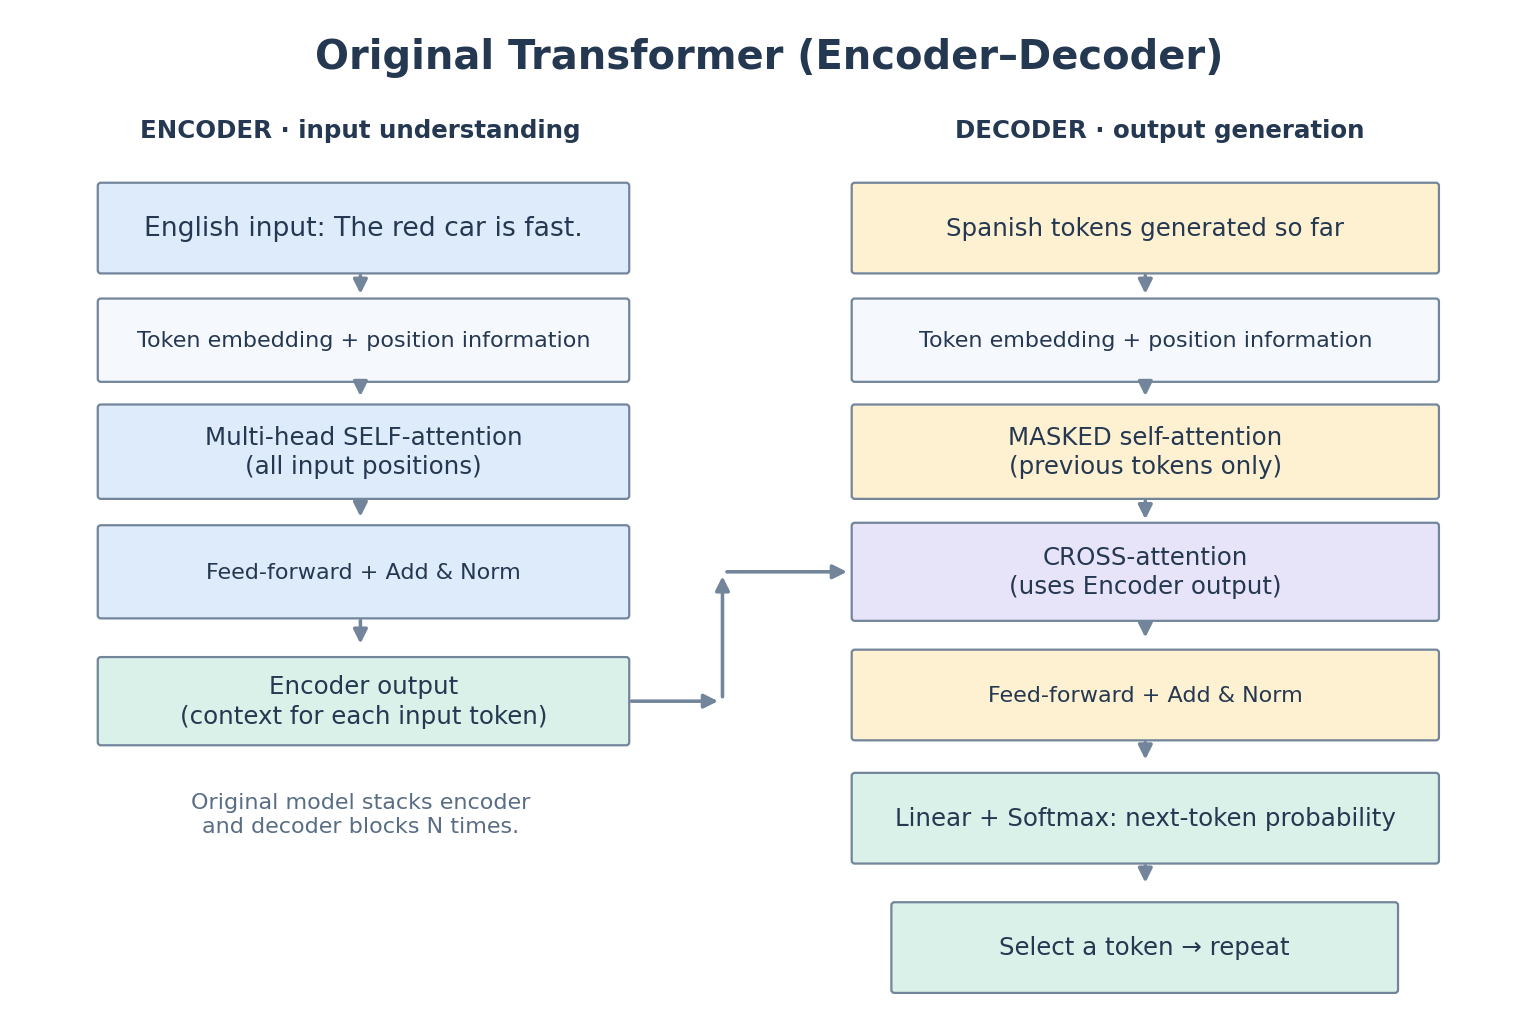

*그림: 원래 Transformer의 주요 블록과 연결을 학부 수준으로 단순화하여 새로 작성. Add & Norm, 반복 블록, 세부 경로 일부는 간략화하였다.*


## 3-1. Encoder: 입력 문장 전체를 처리한다

예: **`The red car is fast.`**

Encoder의 핵심 흐름:

1. 영어 문장을 토큰화하고 임베딩·위치 정보를 더한다.
2. **Self-Attention**으로 각 토큰이 다른 입력 토큰을 참고한다. 원래 Encoder의 Self-Attention은 입력 문장 앞뒤를 모두 참고할 수 있다.
3. Feed-Forward 등 추가 연산을 거쳐 **토큰별 문맥 표현**을 출력한다.

중요: Encoder는 문장을 **하나의 단어**나 **하나의 정수**로 바꾸는 것이 아니다. 여러 입력 토큰 각각에 대해 문맥이 반영된 벡터를 출력한다.

**핵심 질문:** Encoder의 목적은 영어 문장의 단어 순서를 스페인어 순서로 바로 바꾸는 것일까? → 아니다. 스페인어 생성을 돕는 입력 표현을 제공하는 것이다.


## 3-2. Decoder: 앞서 생성한 단어와 입력 문장을 참고한다

Decoder에는 서로 다른 Attention이 두 번 등장한다.

| Decoder 단계 | 참고하는 정보 | 왜 필요한가? |
|---|---|---|
| **Masked Self-Attention** | 이미 생성된 스페인어 토큰들 | 미래에 아직 생성하지 않은 정답을 미리 보지 않기 위해 |
| **Cross-Attention** | Encoder가 만든 영어 문장의 표현 | 어떤 영어 내용을 번역하고 있는지 참고하기 위해 |
| 출력층 | Decoder가 계산한 표현 | 다음 스페인어 토큰의 확률 계산 |

원래 Transformer의 Decoder에는 이 두 Attention 외에도 Feed-Forward, 잔차 연결, 정규화가 포함된다. 지금은 **두 종류의 Attention이 무엇을 참고하는지**가 가장 중요하다.

### 왜 Causal Mask가 필요할까?

스페인어 단어를 왼쪽부터 하나씩 만든다면, 아직 생성하지 않은 오른쪽 단어를 미리 읽을 수 없어야 한다.

| 예측하려는 위치 | 볼 수 있는 출력 쪽 토큰의 예 | 아직 볼 수 없는 토큰 |
|---|---|---|
| 첫 토큰 | `[start]` | 모든 미래 스페인어 토큰 |
| 둘째 토큰 | `[start] El` | 그 뒤의 스페인어 토큰 |
| 셋째 토큰 | `[start] El coche` | 그 뒤의 스페인어 토큰 |

이때도 Decoder는 **Cross-Attention으로 영어 입력 전체를 참고**할 수 있다.


## 3-3. 영어 → 스페인어 번역 예제

입력: **`The red car is fast.`**

가능한 번역: **`El coche rojo es rápido.`**

영어의 `red car`와 스페인어의 `coche rojo`는 단어 순서가 다르다. **영어와 스페인어를 같은 위치끼리 단순 대조하는 방식으로 번역하지 않는다.**

1. Encoder가 영어 문장 전체를 처리한다.
2. Decoder가 `[start]`에서 시작하여 다음 스페인어 토큰을 예측한다.
3. 선택한 토큰을 출력 쪽에 붙이고, 다음 토큰을 계속 예측한다.
4. 종료 토큰이 나오면 번역이 끝난다.

예를 들어:

```text
Encoder 입력: The red car is fast.
Decoder 입력: [start]             → 다음 토큰: El
Decoder 입력: [start] El          → 다음 토큰: coche
Decoder 입력: [start] El coche    → 다음 토큰: rojo
...                               → 마지막 종료 토큰
```

여기에서 `[start]`는 **설명용 표시**이며, 실제 사전훈련 모델의 시작·종료 토큰은 모델마다 다르다.

**주의:** 번역에는 여러 가지 자연스러운 표현이 존재한다. 모델이 생성한 문장을 유일한 정답으로 보지 않는다.


### '모델 훈련'과 '모델 사용'을 구분하자

이번 Lab에서는 번역 모델을 처음부터 훈련하지 않는다.

- **훈련:** 영어·스페인어 문장쌍을 이용하여 모델의 가중치를 조정하는 과정
- **사용(추론):** 이미 훈련된 모델에 **새로운 영어 문장**을 넣어 스페인어 번역을 생성하는 과정

원래 Transformer가 Encoder–Decoder 구조였다는 사실과, 실제 실습 모델이 **사전훈련된 Encoder–Decoder 계열**이라는 점을 연결하는 데 초점을 둔다.


## 3-4. 원래 Transformer에서 LLM으로: 무엇이 달라졌을까?

앞에서는 **Encoder가 입력 문장을 처리하고, Decoder가 번역문을 생성하는 원래 Transformer**를 살펴보았다. 그런데 ChatGPT와 같은 생성형 언어 모델은 왜 별도의 Encoder 없이도 질문에 답하고 글을 쓸 수 있을까?

핵심은 **신경망의 구조(아키텍처)**와 **그 구조를 실제 데이터로 학습한 모델**을 구분하는 것이다.

- **Transformer:** Attention을 이용해 토큰 정보를 처리하는 *신경망 설계 방식*이다. 2017년에 제안된 원래 형태는 Encoder와 Decoder를 함께 사용했다.
- **Decoder-only Transformer:** 원래 구조에서 별도의 Encoder 및 Encoder와 연결하는 Cross-Attention 없이, 주로 **Causal Self-Attention**으로 앞선 토큰을 참고하며 다음 토큰을 예측하도록 만든 구조다. GPT 계열이 대표적이다.
- **LLM(Large Language Model):** 대규모 텍스트·코드 등의 데이터로 학습한 언어 모델을 말한다. 현대의 많은 생성형 LLM은 Decoder-only Transformer 기반이지만, **모든 LLM이 Decoder-only인 것은 아니다.**

### 모델이 문장을 생성할 수 있게 되는 과정

```text
Decoder-only Transformer 구조
       ↓
대규모 텍스트로 사전훈련(Pretraining)
: 앞선 토큰들을 보고 다음 토큰을 맞히도록 학습
       ↓
사전훈련된 언어 모델
       ↓
(선택적으로) 질문·답변 등의 예제로 추가 학습
       ↓
프롬프트를 받아 이어쓰기·질의응답 수행
```

예를 들어 `The capital of Spain is`라는 문장이 주어지면, 모델은 다음 토큰 후보들에 확률을 부여한다. 하나를 선택해 입력 뒤에 붙이고 **다음 토큰 예측을 반복**하면 문장이 생성된다. 이러한 원리는 번역 Decoder에서도 사용했지만, Decoder-only 모델에서는 **영어 입력을 처리하는 별도의 Encoder가 필요하지 않다.**

**기억할 점:** 다음 토큰 예측은 사전훈련의 주요 학습 목표이자 텍스트 생성의 핵심 원리다. 그러나 다음 토큰을 잘 예측하는 것과 **사실에 맞고 사용자의 지시를 잘 따르는 것**은 동일하지 않다. 지시문을 따르는 모델에는 추가 학습이 활용될 수 있으며, 이번 P4에서는 **학습 과정 자체를 구현하지 않고 사전훈련된 모델을 사용**한다.


### 3-5. Transformer의 세 구조는 오늘날 어디에 사용할까?

원래 Transformer의 **Encoder와 Decoder를 함께 쓰는 방식** 외에도, 목적에 따라 한쪽만 사용하는 모델이 발전했다.

| 구조 | 대표 모델 | 현재의 주요 활용 | 학생들이 기억할 점 |
|---|---|---|---|
| **Encoder-only** | BERT, Sentence-BERT 계열 | 감성분석, 문서 분류, **의미 기반 검색** | 입력 텍스트를 분석하고 의미를 벡터로 표현한다. |
| **Encoder–Decoder** | MarianMT, T5, BART, Whisper | **번역**, 문서 요약, 음성 인식 | 입력을 처리한 뒤 다른 시퀀스를 생성한다. |
| **Decoder-only** | GPT, Llama 계열 | **텍스트 생성**, 질의응답, 코드 작성 | 프롬프트 뒤의 다음 토큰을 반복해서 예측한다. |

**간단한 사례:** 검색창에 `강아지를 키우는 방법`을 입력하면, Encoder 계열 임베딩 모델은 문장의 *의미*를 수치 벡터로 나타내어 `반려견 돌봄 안내`처럼 표현이 다른 관련 문서도 찾는 데 활용할 수 있다. 반면 번역 모델은 `The dog is sleeping.`을 스페인어 문장으로 변환하고, Decoder-only 모델은 `Once upon a time...` 뒤의 이야기를 계속 생성한다.

> **주의:** 이는 구조별 **대표적 활용**이지 엄격한 용도 구분은 아니다. Decoder-only 모델도 번역·요약을 할 수 있고, 모든 검색용 임베딩 모델이 Encoder-only인 것도 아니다. 이 P4 Lab에서는 **번역과 텍스트 생성**을 실습하고, P4 Project에서는 **Encoder 계열의 문서 검색**을 사용한다.


## 3-6. Encoder-only: 문장 임베딩과 의미 검색

Encoder-only Transformer는 입력 문장을 **양방향 Self-Attention**으로 처리하여 문맥을 반영한 표현을 계산한다. BERT와 같은 인코더를 기반으로 만든 **문장 임베딩 모델**은 문장 전체를 하나의 벡터로 표현할 수 있다. (*BERT 자체의 모든 출력이 자동으로 문장 임베딩이 되는 것은 아니며, 문장 유사도에 적합하게 학습·구성된 모델을 사용한다.*)

예를 들어 `야생동물을 같은 개체로 중복 계산하지 않으려면?`이라는 질문을 받았다고 하자.

- 문서 A: `카메라에 같은 동물이 반복 등장하면 관측 횟수와 개체 수를 구분해야 한다.`
- 문서 B: `카메라 배터리는 매주 점검한다.`

문서 A에 질문과 **완전히 같은 단어가 없어도**, 의미가 비슷하면 검색 결과의 상위에 나타날 수 있다.

```text
질문 ------------------→ 문장 임베딩 모델 → 질문 벡터
문서 A, B, ... --------→ 문장 임베딩 모델 → 문서 벡터들
                                           ↓
                                  벡터의 유사도 비교
                                           ↓
                                  관련 문서 상위 3개
```

- **토큰 임베딩:** 한 토큰을 숫자 벡터로 나타낸다.
- **문장 임베딩:** 문장 또는 짧은 문서를 대표하는 하나의 숫자 벡터로 나타낸다.
- **의미 검색:** 질문 벡터와 문서 벡터의 유사도를 비교해 관련 문서를 찾는다. 흔히 **코사인 유사도**를 사용하지만, 이번에는 복잡한 수학적 계산 대신 *의미가 가까운 벡터를 찾는다*는 원리만 이해한다.

**주의:** 유사도가 높다는 것은 내용이 관련 있을 가능성이 높다는 뜻이지, **문서가 사실이라는 뜻은 아니다.**

## 3-7. 두 구조의 협력: RAG(검색 증강 생성)

의미 검색만으로는 문서를 찾아 보여줄 수 있지만, 질문에 대한 **완성된 문장 형태의 답변**을 작성하지는 않는다. 반대로 Decoder-only 언어 모델에 질문만 넣으면 관련 문서를 확인하지 않고 답변을 생성할 수 있다.

**RAG(Retrieval-Augmented Generation, 검색 증강 생성)**는 이 두 과정을 연결한다.

```text
사용자 질문: "중복 관측 문제는 어떻게 해결하나요?"
                  ↓
① Encoder-only 기반 임베딩 모델
   → 질문과 관련된 문서 25개 중 상위 3개 검색
                  ↓
② 검색된 문서 3개 + 사용자 질문
   → Decoder-only 언어 모델에 함께 입력
                  ↓
③ 문서 내용에 근거한 답변 생성
   → 실제 근거와 일치하는지는 사람이 확인
```

| 단계 | 핵심 기능 | P4에서 사용하는 곳 |
|---|---|---|
| Encoder–Decoder | 입력 시퀀스를 다른 시퀀스로 변환 | **Lab:** 영어→스페인어 번역 |
| Encoder-only | 질문·문서를 벡터로 바꾸어 관련 문서 검색 | **Project:** 의미 검색 |
| Decoder-only | 검색된 문서를 참고하여 다음 토큰을 반복 생성 | **Project:** 답변 생성 |

**P4 Project 연결:** 사전에 준비한 **가상 '한솔 생태관측소' 안내 문서 25개**를 사용한다. 학생들은 *단어 일치 검색과 의미 검색*을 비교하고, 검색된 문서를 근거로 생성한 답변에 **문서에 없는 주장이 들어 있는지** 점검한다.

이 과정은 **모델을 새로 학습하지 않고**, 이미 학습된 모델 두 개를 연결해서 사용한다. RAG는 잘못된 답변을 줄이는 데 도움이 될 수 있지만 **항상 정확한 답을 보장하지는 않는다.**

---
# 4. Decoder-only: Encoder 없이도 문장을 생성할까?

GPT 계열처럼 **Decoder만 여러 층 쌓은 모델**을 Decoder-only라고 한다. 영어 원문과 출력 언어를 각각 다른 구성 요소로 분리하지 않고, **모든 입력을 하나의 토큰 시퀀스(프롬프트)**로 처리한다.

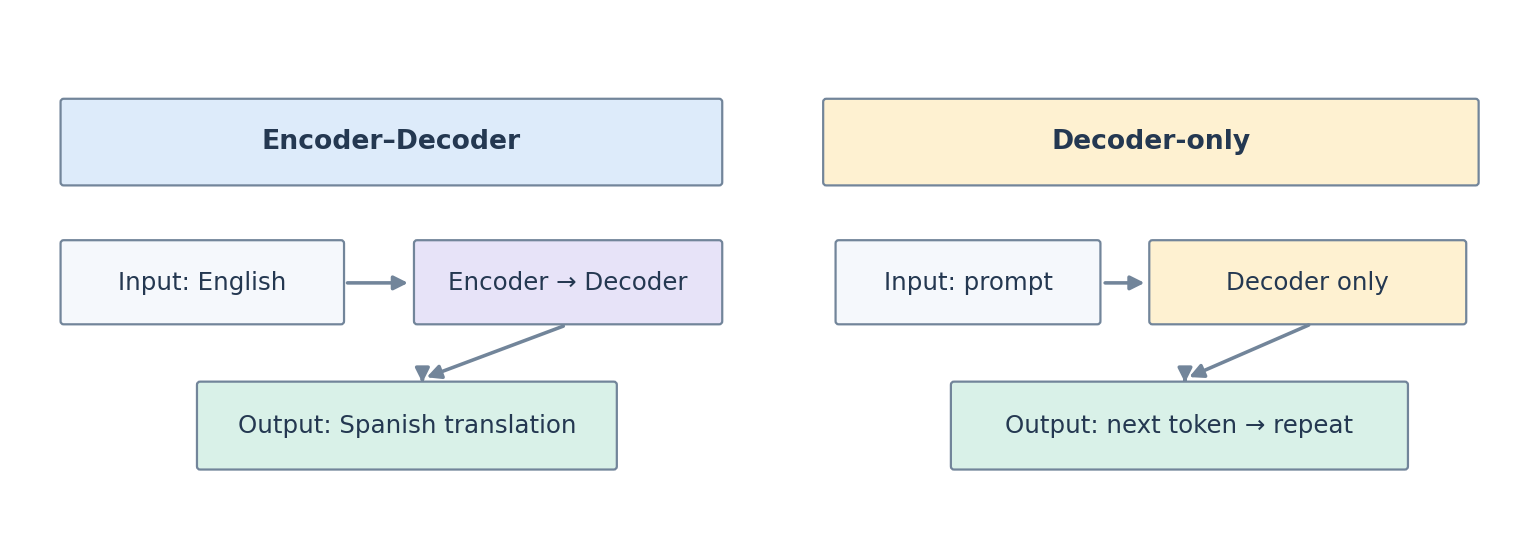

> 주의: Decoder-only의 블록은 원래 Encoder–Decoder의 Decoder를 그대로 복사한 것이 아니다. **Encoder와 연결되는 Cross-Attention은 없고**, 주로 Causal Self-Attention을 사용한다.


## 4-1. 다음 토큰의 확률분포

예를 들어 모델에 다음과 같이 입력한다.

**`The capital of France is`**

모델은 가능한 다음 **토큰** 각각에 확률을 부여한다.

| 후보 토큰 | 예시 확률 |
|---|---:|
| ` Paris` | 0.65 |
| ` Lyon` | 0.08 |
| ` a` | 0.07 |
| 그 밖의 토큰 | 0.20 |

위 확률은 **설명을 위한 가상 값**이다. 실제 확률은 사전훈련된 작은 모델에서 확인한다.

선택된 다음 토큰을 입력 뒤에 붙여 같은 과정을 반복하면 문장이 길어진다.

```text
The capital of France is
The capital of France is Paris
The capital of France is Paris.
```

이것을 **자기회귀적 생성(Autoregressive Generation)**이라고 한다. 원래 Transformer의 Decoder가 다음 스페인어 토큰을 예측하는 과정과 공통된 원리다.


## 4-2. Decoder-only의 간단한 활용 두 가지

**활용 ① 텍스트 이어쓰기**

- 입력: `Continue this story: A small dog opened the door...`
- 출력: 주어진 문맥에 이어지는 새로운 문장
- 관찰: 프롬프트가 달라지면 출력도 달라진다.

**활용 ② 간단한 질의응답**

- 입력: `What is the capital of Spain?`
- 출력: 모델이 생성한 답변 텍스트
- 관찰: '답'도 별도의 정답 조회 버튼이 아니라 **다음 토큰 생성을 반복한 결과**다.

둘 다 같은 Decoder-only 생성 원리를 이용한다. 다만 **작은 교육용 모델은 틀리거나 부자연스러운 답변을 생성할 수 있다.**


## 4-3. 전체 구조를 한 번에 비교

| 구분 | 원래 Transformer Encoder | 원래 Transformer Decoder | Decoder-only 모델 |
|---|---|---|---|
| 주요 역할 | 입력 문장 처리 | 출력 문장 생성 | 프롬프트를 바탕으로 다음 토큰 생성 |
| Self-Attention | 입력 문장 전체 참고 | 이전 출력 토큰만 참고 | 이전 입력·생성 토큰만 참고 |
| Cross-Attention | 없음 | **Encoder 출력 참고** | **없음** |
| 대표 활용 | 번역 모델의 입력 처리 | 번역 모델의 출력 생성 | 이어쓰기, 질의응답 등 |

**정리:** Decoder-only 모델 역시 번역을 수행할 수 있다. 여기서는 **구조의 차이를 명확히 보여주기 위해** Encoder–Decoder는 영어→스페인어 번역으로, Decoder-only는 이어쓰기·질의응답으로 예를 든다.


---
# 5. 학습 내용 확인

1. `token`과 `token ID`는 어떤 차이가 있을까? 임베딩은 왜 필요한가?
2. Q, K, V의 역할을 책 검색에 비유해 설명해 보자.
3. 원래 Transformer의 Encoder 출력은 Decoder의 어느 단계에서 사용되는가?
4. Decoder의 **Masked Self-Attention**과 **Cross-Attention**은 무엇을 다르게 참고하는가?
5. Encoder–Decoder와 Decoder-only의 가장 중요한 구조적 차이는 무엇인가?
6. 작은 언어 모델의 답변이 자연스럽지 않더라도 다음 토큰 생성 원리를 관찰할 수 있는가?
7. **Transformer 구조**와 **사전훈련된 LLM**은 무엇이 다른가?
8. 문장 임베딩 모델은 표현이 다른 질문과 문서를 어떻게 연결하는가?
9. RAG에서는 검색과 답변 생성 중 무엇을 Encoder 계열과 Decoder-only가 각각 담당하는가?

**다음:** `P4_lab_transformer_llm_RAG_revised.ipynb`에서 토큰·Attention·번역·생성을 관찰한 뒤, `P4_project_document_search_RAG.ipynb`에서 실제 검색과 근거 기반 답변 생성을 실험한다.

### 참고 자료

- 기존 강의 노트북: `dl_for_text.ipynb` (제공 자료)
- Vaswani et al. (2017), *Attention Is All You Need*
- Stanford CME295 (Autumn 2026), Lectures 1–3 (제공 슬라이드)
- [Helsinki-NLP 영어→스페인어 번역 모델](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)
- [SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)
